In [13]:
from pathlib import Path
import csv
import hashlib
import json
import random

import numpy as np
import pandas as pd
import yfinance as yf
from lppls import lppls
from tqdm.auto import tqdm

# Parametry oryginalnego eksperymentu
TICKER = "BTC-USD"
START = "2015-01-01"
END_EXCLUSIVE = "2025-01-01"  # dzień 31.12.2024 będzie uwzględniony
MIN_WIN = 30
MAX_WIN = 180
STEP = 5
MAX_SEARCHES = 50
SEED = 42

OUTPUT_FILE = Path("lppls_rolling_all_fits_2015_2024.csv")
BATCH_SIZE = 200  # tylko częstotliwość dopisywania do tego samego CSV

COLUMNS = [
    "window_id", "run_id", "win_start", "win_end", "n", "ok", "err",
    "tc", "m", "w", "A", "B", "C", "c1", "c2", "O", "D",
    "ssr", "r2", "t_gap"
]


c:\Users\cynar\Desktop\projects\article_stock_bubbles\venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\cynar\Desktop\projects\article_stock_bubbles\venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\cynar\Desktop\projects\article_stock_bubbles\venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.

735060.7127440763 0.15735309211876483 11.90987359739238 -12.844942849834457 6.525754205069402 0.15379170321587401 0.1432806947769785 0.055879607033924306 -3.8898479226867484 0.5606165759534876


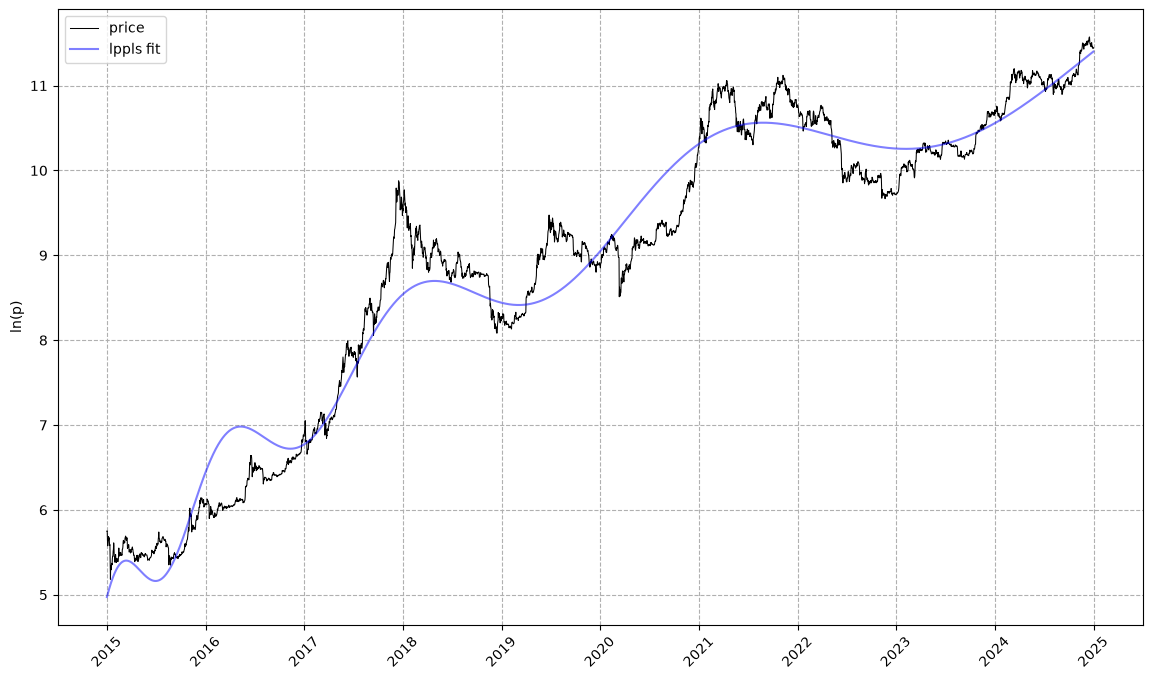

In [24]:
# 1) Dane
data = yf.download("BTC-USD", start="2015-01-01", end="2025-01-01")
# data = yf.download("^GSPC", start="2000-01-01", end="2025-08-31")

data = data.reset_index()

price_col = "Adj Close" if "Adj Close" in data.columns else "Close"
df = data[["Date", price_col]].dropna().sort_values("Date").reset_index(drop=True)
df = df.rename(columns={price_col: "price"})

# 2) Wektory czasu i ceny (1D)
time = df["Date"].map(pd.Timestamp.toordinal).to_numpy(dtype=float)
price = np.log(df["price"].to_numpy(dtype=float))

# 3) Jednolita filtracja niefinitych wierszy (unikamy problemów z maską)
stack = np.column_stack([time, price])             # shape (N, 2)
stack = stack[np.isfinite(stack).all(axis=1)]      # tylko wiersze w pełni „finite”
time, price = stack[:, 0], stack[:, 1]             # z powrotem na 2 wektory 1D

# 4) Observations: (2, N)
observations = np.vstack([time, price])

# 5) LPPLS
MAX_SEARCHES = 50
model = lppls.LPPLS(observations=observations)
tc, m, w, a, b, c, c1, c2, O, D = model.fit(MAX_SEARCHES)
model.plot_fit(show_tc=True)
print(tc, m, w, a, b, c, c1, c2, O, D)

In [ ]:
df = df.copy() 
df["t_ord"] = df["Date"].map(pd.Timestamp.toordinal).astype(float) 
df["logp"] = np.log(df["price"].astype(float)) 

# Ustawienia okien 
MIN_WIN = 30
MAX_WIN = 180
STEP = 5 
MAX_SEARCHES = 50 
records = [] 
def fit_lppls_on_window(t, p, max_searches=50): 
    obs = np.vstack([t, p]) 
    model = lppls.LPPLS(observations=obs) 
    try: 
        tc, m, w, A, B, C, c1, c2, O, D = model.fit(max_searches) 
    except Exception as e: 
        return {"ok": False, "err": str(e)} 
    
    p_hat = model.lppls(t, tc, m, w, A, B, c1, c2) 
    resid = p - p_hat 
    ssr = float(np.sum(resid**2)) 
    sst = float(np.sum((p - p.mean())**2)) 
    r2 = float(1.0 - ssr / sst) if sst > 0 else np.nan 
    # t_start = float(t[0])
    t_end = float(t[-1]) 
    
    ok_m = (0 < m < 1) 
    # ok_m = (0 < m < 1.5) 
    ok_w = (6 <= w <= 13) 
    # ok_w = (4 <= w <= 16) 
    ok_B = (B < 0) 
    # ok_tc = (tc > t_end)
    ok_tc = (0 < (tc - t_end) <= 40)
    # ok_tc = (tc > t_start) & (tc <= t_end + 30)
    ok_r2 = (r2 > 0.9) 
 
    
    return {
        "ok": True,
        "tc": float(tc), "m": float(m), "w": float(w),
        "A": float(A), "B": float(B), "C": float(C),
        "c1": float(c1), "c2": float(c2),
        "O": float(O), "D": float(D),
        "ssr": ssr, "r2": r2,
        "cond_m": ok_m, "cond_w": ok_w, "cond_B": ok_B, "cond_tc": ok_tc
    }
 # Pętla po oknach: różne długości i przesunięcia 
N = len(df)
for start in tqdm(range(0, N - MIN_WIN + 1, STEP), desc="Rolling windows"):
    for L in range(MIN_WIN, min(MAX_WIN, N - start) + 1):
        end = start + L
        t_win = df["t_ord"].to_numpy()[start:end]
        p_win = df["logp"].to_numpy()[start:end]
        res = fit_lppls_on_window(t_win, p_win)

        row = {
            "win_start": df.loc[start, "Date"],
            "win_end":   df.loc[end-1, "Date"],
            "n": L,
        }
        row.update(res)
        records.append(row)

rolling_results = pd.DataFrame.from_records(records)


C:\Users\cynar\AppData\Local\Temp\ipykernel_34720\2737476861.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df["t_ord"] = df["Date"].map(pd.Timestamp.toordinal).astype(float)
C:\Users\cynar\AppData\Local\Temp\ipykernel_34720\2737476861.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df["logp"] = np.log(df["price"].astype(float))
Rolling windows: 100%|██████████| 725/725 [1:39:30<00:00,  8.24s/it]  


In [26]:
rolling_results.to_csv("lppls_rolling_results.csv", index=False)

In [30]:
rolling_results

,win_start,win_end,n,ok,tc,m,w,A,B,C,c1,c2,O,D,ssr,r2,cond_m,cond_w,cond_B,cond_tc
0,2015-01-01,2015-01-30,30,True,7.355947e+05,0.966525,6.720100,5.798027,-1.953252e-02,-9.690943e-03,-7.015534e-03,-6.685556e-03,-2.195625,0.289888,0.063431,0.894214,True,True,True,False
1,2015-01-01,2015-01-31,31,True,7.356358e+05,0.692946,6.055410,5.450283,2.417122e-03,-1.917749e-02,-1.374716e-02,1.337131e-02,1.625319,0.014423,0.117710,0.808814,True,True,False,True
2,2015-01-01,2015-02-01,32,True,8.063716e+05,0.767180,5.289823,0.063901,5.781582e+01,5.781480e+01,4.708358e+01,-3.355126e+01,0.000369,0.145032,0.299048,0.519356,True,False,False,False
3,2015-01-01,2015-02-02,33,True,8.216148e+05,0.700389,5.650351,0.129405,1.311957e+02,-1.311938e+02,-2.646339e+01,-1.284971e+02,0.000335,0.123957,0.301119,0.516747,True,False,False,False
4,2015-01-01,2015-02-03,34,True,2.293064e+06,5.738598,126.985986,0.087918,6.442018e-31,-6.441863e-31,-3.039593e-31,-5.679654e-31,0.000428,0.045192,0.309646,0.507623,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107235,2024-11-24,2024-12-31,38,True,7.393130e+05,0.517513,14.371407,11.376402,1.210495e-02,3.884655e-03,3.793278e-03,-8.376054e-04,1.070397,0.112210,0.016897,0.619910,True,False,False,False
107236,2024-11-29,2024-12-28,30,True,7.392792e+05,0.457447,11.766092,11.412949,1.609576e-02,5.549252e-03,4.696243e-03,2.956264e-03,1.229940,0.112768,0.012622,0.556400,True,True,False,True
107237,2024-11-29,2024-12-29,31,True,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,4097.757430,-131533.868122,False,False,False,False
107238,2024-11-29,2024-12-30,32,True,7.393856e+05,4.228021,32.963822,11.426488,4.422322e-11,-2.174140e-11,-2.881202e-12,2.154965e-11,1.079984,0.260893,0.013546,0.609801,False,False,False,False
